# Bank Customer Churn Prediction

### Objective:
Predict whether a bank customer will leave the bank in the next 6 months using a **neural network**.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix

import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense, Input

### Load the Dataset

In [14]:
df = pd.read_csv("Churn_Modelling.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [15]:
print("Initial shape:", df.shape)

Initial shape: (10000, 14)


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


### Preprocessing


In [17]:
# Drop irrelevant columns
df = df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)

In [18]:
# Encode categorical variables
le_gender = LabelEncoder()
df['Gender'] = le_gender.fit_transform(df['Gender'])

# One hot encoding
df = pd.get_dummies(df, columns=['Geography'], dtype=int)

In [19]:
df.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_France,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,1,0,0
1,608,0,41,1,83807.86,1,0,1,112542.58,0,0,0,1
2,502,0,42,8,159660.80,3,1,0,113931.57,1,1,0,0
3,699,0,39,1,0.00,2,0,0,93826.63,0,1,0,0
4,850,0,43,2,125510.82,1,1,1,79084.10,0,0,0,1


In [20]:
# Split features and target
X = df.drop('Exited', axis=1)
y = df['Exited']

# Train-test split (80-20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [21]:
# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Build Neural Network

In [25]:
def build_and_train_nn(X_train, y_train, X_test, y_test,
                       hidden_layers=[64, 32],
                       activation='relu',
                       epochs=50):

    # Initialize model
    model = Sequential()

    # Input layer
    model.add(Input(shape=(X_train.shape[1],)))

    # First hidden layer
    model.add(Dense(hidden_layers[0], activation=activation))

    # Remaining hidden layers
    for units in hidden_layers[1:]:
        model.add(Dense(units, activation=activation))

    # Output layer
    model.add(Dense(1, activation='sigmoid'))

    # Compile
    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    # Train
    history = model.fit(
        X_train,
        y_train,
        validation_split=0.2,
        epochs=epochs,
        batch_size=32,
        verbose=0
    )

    # Predictions
    y_pred = (model.predict(X_test, verbose=0) > 0.5).astype(int)

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    print(f"Activation: {activation}, Epochs: {epochs}")
    print(f"Accuracy: {acc:.3f}")
    print("Confusion Matrix:\n", cm)

    return model, history

In [26]:
# Experiment with different epochs using only the ReLU activation
activations = ['relu']
epochs_list = [25, 50, 75]

results = []

for act in activations:
    for ep in epochs_list:
        model, history = build_and_train_nn(X_train_scaled, y_train, X_test_scaled, y_test,
                                            activation=act, epochs=ep)
        results.append((act, ep, model, history))

Activation: relu, Epochs: 25
Accuracy: 0.857
Confusion Matrix:
 [[1518   75]
 [ 211  196]]
Activation: relu, Epochs: 50
Accuracy: 0.856
Confusion Matrix:
 [[1537   56]
 [ 232  175]]
Activation: relu, Epochs: 75
Accuracy: 0.850
Confusion Matrix:
 [[1472  121]
 [ 180  227]]


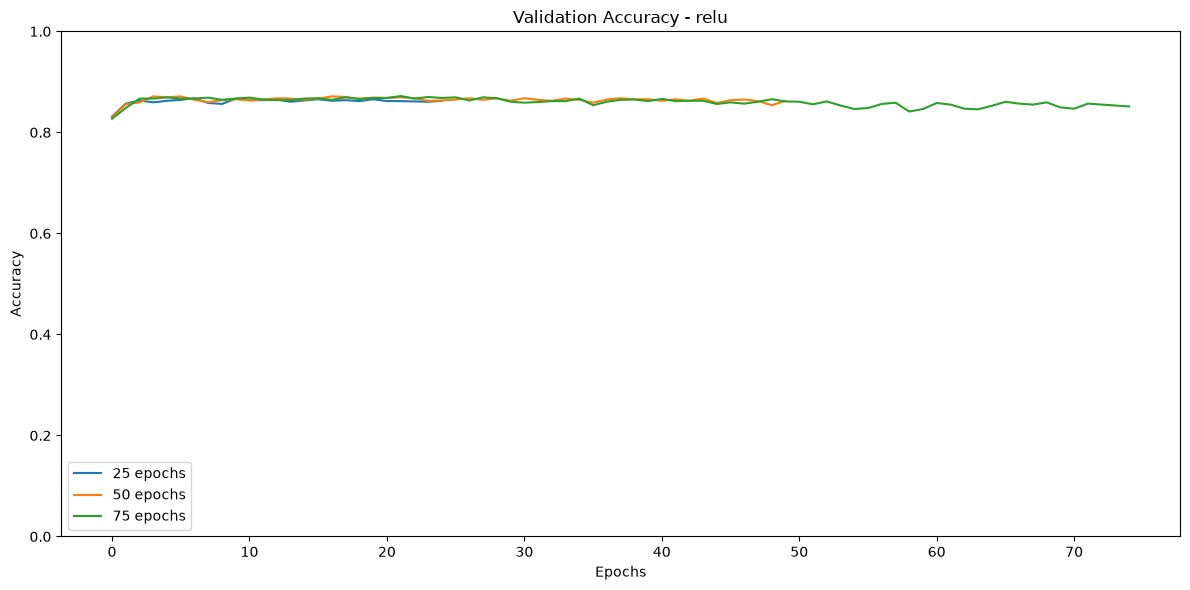

In [24]:
import matplotlib.pyplot as plt

# One subplot per activation function
activations = sorted(list(set([r[0] for r in results])))
epochs_list = sorted(list(set([r[1] for r in results])))

plt.figure(figsize=(12, 6))

for i, act in enumerate(activations):
    plt.subplot(1, len(activations), i+1)

    for act_r, ep, model, history in results:
        if act_r == act:
            plt.plot(history.history['val_accuracy'], label=f'{ep} epochs')

    plt.title(f'Validation Accuracy - {act}')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0, 1)
    plt.legend()

plt.tight_layout()
plt.show()